# Tutorial: what can prospect theory predict?

*A worked example of parameter space partitioning: map every pattern of choices prospect theory can make on four classic bets, and check whether the pattern people actually choose is among them.*

Suppose you have a model of how people choose between bets. You can fit it to data and find the parameter values that describe people best. Parameter space partitioning (PSP) asks a different question: **what is the model capable of predicting at all?** It searches the model's parameters for every qualitatively different pattern of behaviour the model can produce (Pitt, Kim, Navarro & Myung, 2006). That tells you two things a fit cannot:

- whether the model can produce the pattern people actually show, and how much of its parameter space does so;
- what *else* the model can produce. A model that can predict almost any pattern explains little when it happens to predict the right one.

This tutorial works through one complete analysis with `psp`: prospect theory, a famous model of risky choice, and four bets from the paper that introduced it. It is the PyTorch counterpart of the [tutorial of the R package](https://lenarddome.com/psp/articles/tutorial.html), and follows it step for step.

In [1]:
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib import patches as mpatches
from matplotlib.lines import Line2D

from psp import PSP, read_saved
from figure_style import figures, titled

show = figures("tutorial")

blue, grey = "#2a78d6", "#adb5bd"


## Four bets

Kahneman and Tversky (1979) asked people to choose between pairs of bets. In each pair, one option is *riskier*: it pays more but is less likely to pay out. The other is *safer*.

In [2]:
problems = pd.DataFrame({
    "problem": [3, 4, 7, 8],
    "risky_amount": [4000, 4000, 6000, 6000],
    "risky_chance": [0.80, 0.20, 0.45, 0.001],
    "safe_amount": [3000, 3000, 3000, 3000],
    "safe_chance": [1, 0.25, 0.90, 0.002],
    "chose_risky": [20, 65, 14, 73],   # percentage of people
    "people": [95, 95, 66, 66],
})
problems

,problem,risky_amount,risky_chance,safe_amount,safe_chance,chose_risky,people
0,3,4000,0.800,3000,1.000,20,95
1,4,4000,0.200,3000,0.250,65,95
2,7,6000,0.450,3000,0.900,14,66
3,8,6000,0.001,3000,0.002,73,66


| Problem | Riskier option | Safer option | People |
|---|---|---|---|
| 3 | 80% chance of 4,000 | 3,000 for sure | 95 |
| 4 | 20% chance of 4,000 | 25% chance of 3,000 | 95 |
| 7 | 45% chance of 6,000 | 90% chance of 3,000 | 66 |
| 8 | 0.1% chance of 6,000 | 0.2% chance of 3,000 | 66 |

The problems come in two matched pairs. Problem 4 is Problem 3 with both chances divided by four, and Problem 8 is Problem 7 with both chances divided by 450. Here is what people chose:

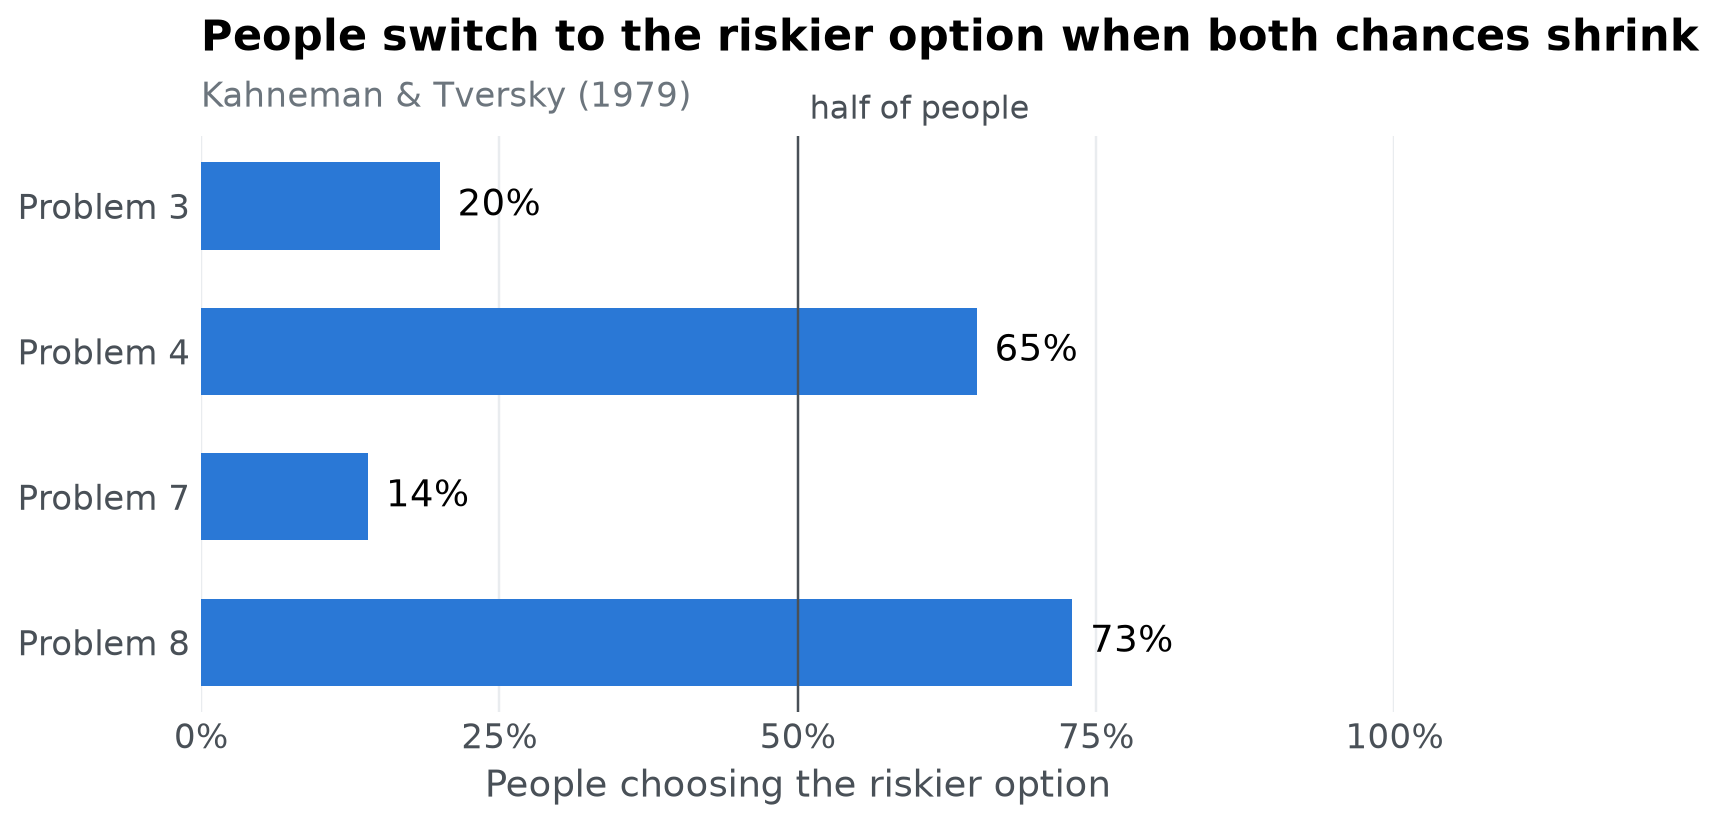

In [3]:
labels = [f"Problem {p}" for p in problems.problem]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(labels[::-1], problems.chose_risky[::-1], color=blue, height=0.6)
ax.axvline(50, color="#495057", linewidth=0.8)
for y, value in enumerate(problems.chose_risky[::-1]):
    ax.text(value + 1.5, y, f"{value}%", va="center")
ax.text(51, 3.6, "half of people", color="#495057", fontsize=10.5)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 25), [f"{x}%" for x in range(0, 101, 25)])
ax.set_xlabel("People choosing the riskier option")
ax.grid(axis="y", visible=False)
titled(ax, "People switch to the riskier option when both chances shrink", "Kahneman & Tversky (1979)")
show(fig, "kahneman-tversky-choices")

Most people take the safer option in Problems 3 and 7, but the riskier option in Problems 4 and 8. This switch is a problem for expected utility theory, the classical account of rational choice. Dividing both chances by the same number should never change which option you prefer, yet it does here. Can prospect theory produce this pattern of choices, and what else can it produce?

## The model

### Prospects

Each option is a *prospect*: an amount of money $x$ won with probability $p$, and nothing otherwise. A sure thing is a prospect with $p = 1$. Prospect theory gives every prospect a subjective value

$$
V(x, p) = w(p)\, v(x),
$$

the product of how much the money is worth to the person, $v(x)$, and how much weight they give its chance of happening, $w(p)$. Each of these has one free parameter.

### How much money is worth: $\alpha$

$$
v(x) = x^{\alpha}, \qquad 0 < \alpha \le 1.
$$

The parameter $\alpha$ (alpha) controls diminishing sensitivity. With $\alpha = 1$, value is proportional to money: 6,000 is worth exactly twice 3,000. The smaller $\alpha$, the less each extra pound adds, so a sure 3,000 starts to look nearly as good as a chance of 4,000.

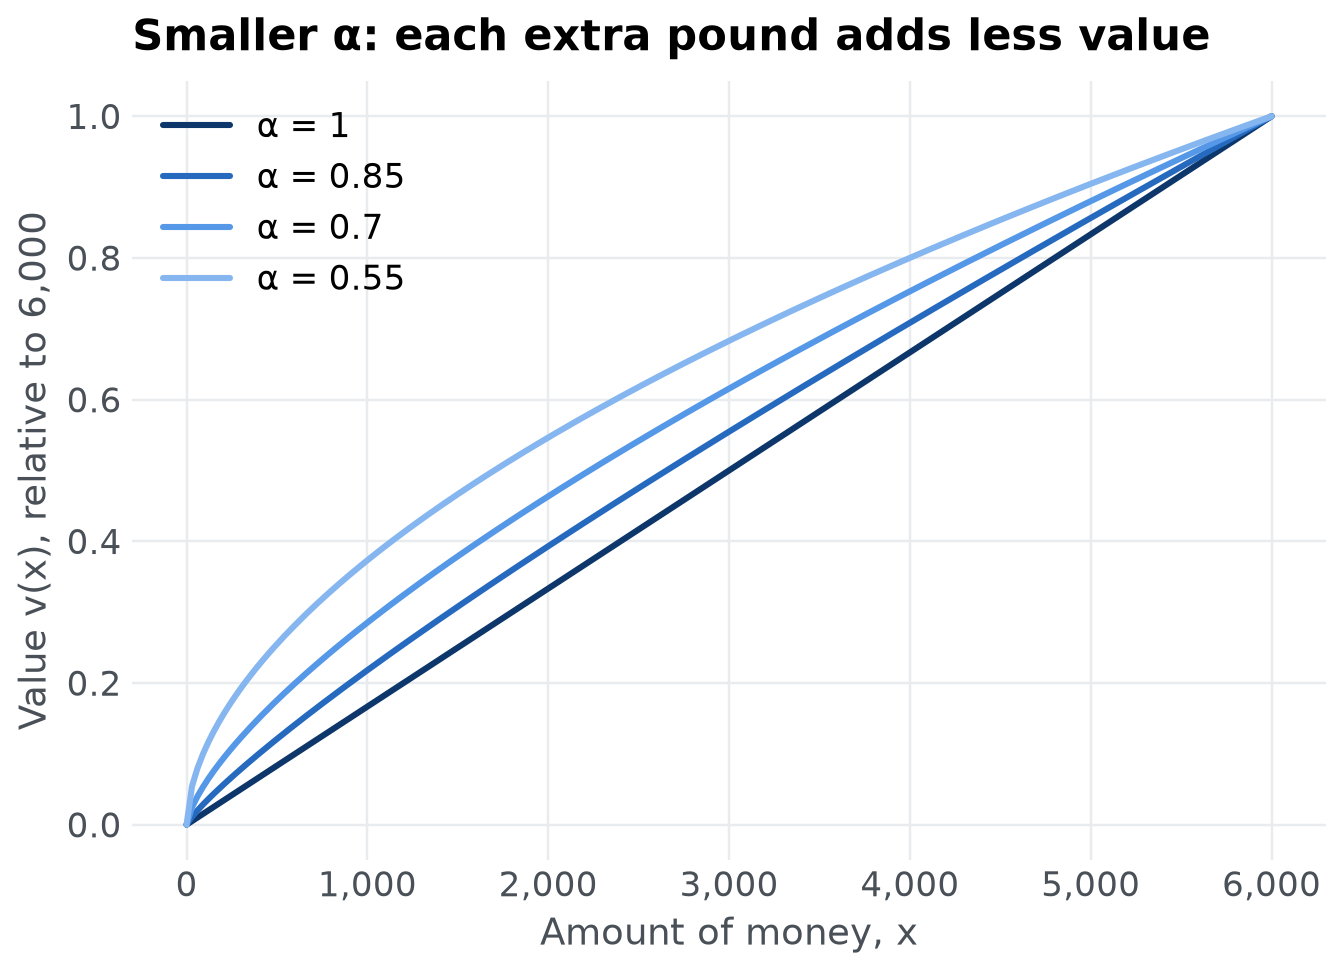

In [4]:
alphas = [1, 0.85, 0.7, 0.55]
alpha_colours = {1: "#0d366b", 0.85: "#256abf", 0.7: "#5598e7", 0.55: "#86b6ef"}
x = np.linspace(0, 6000, 201)
fig, ax = plt.subplots()
for a in alphas:
    ax.plot(x, x**a / 6000**a, color=alpha_colours[a], linewidth=2, label=f"α = {a}")   # scaled so all curves end at 1
ax.set_xlabel("Amount of money, x")
ax.set_ylabel("Value v(x), relative to 6,000")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend()
titled(ax, "Smaller α: each extra pound adds less value")
show(fig, "value-function")

### How much a chance counts: $\gamma$

$$
w(p) = \frac{p^{\gamma}}{\left(p^{\gamma} + (1 - p)^{\gamma}\right)^{1/\gamma}}.
$$

The probability weighting function $w(p)$ turns an objective chance into a decision weight, and the parameter $\gamma$ (gamma) controls its shape (Tversky & Kahneman, 1992). With $\gamma = 1$, $w(p) = p$ and chances count at face value. With $\gamma < 1$, small chances are *overweighted* and large chances *underweighted*, giving the inverse-S shape below. With $\gamma > 1$ the bend reverses. A sure thing always has weight 1, whatever $\gamma$ is.

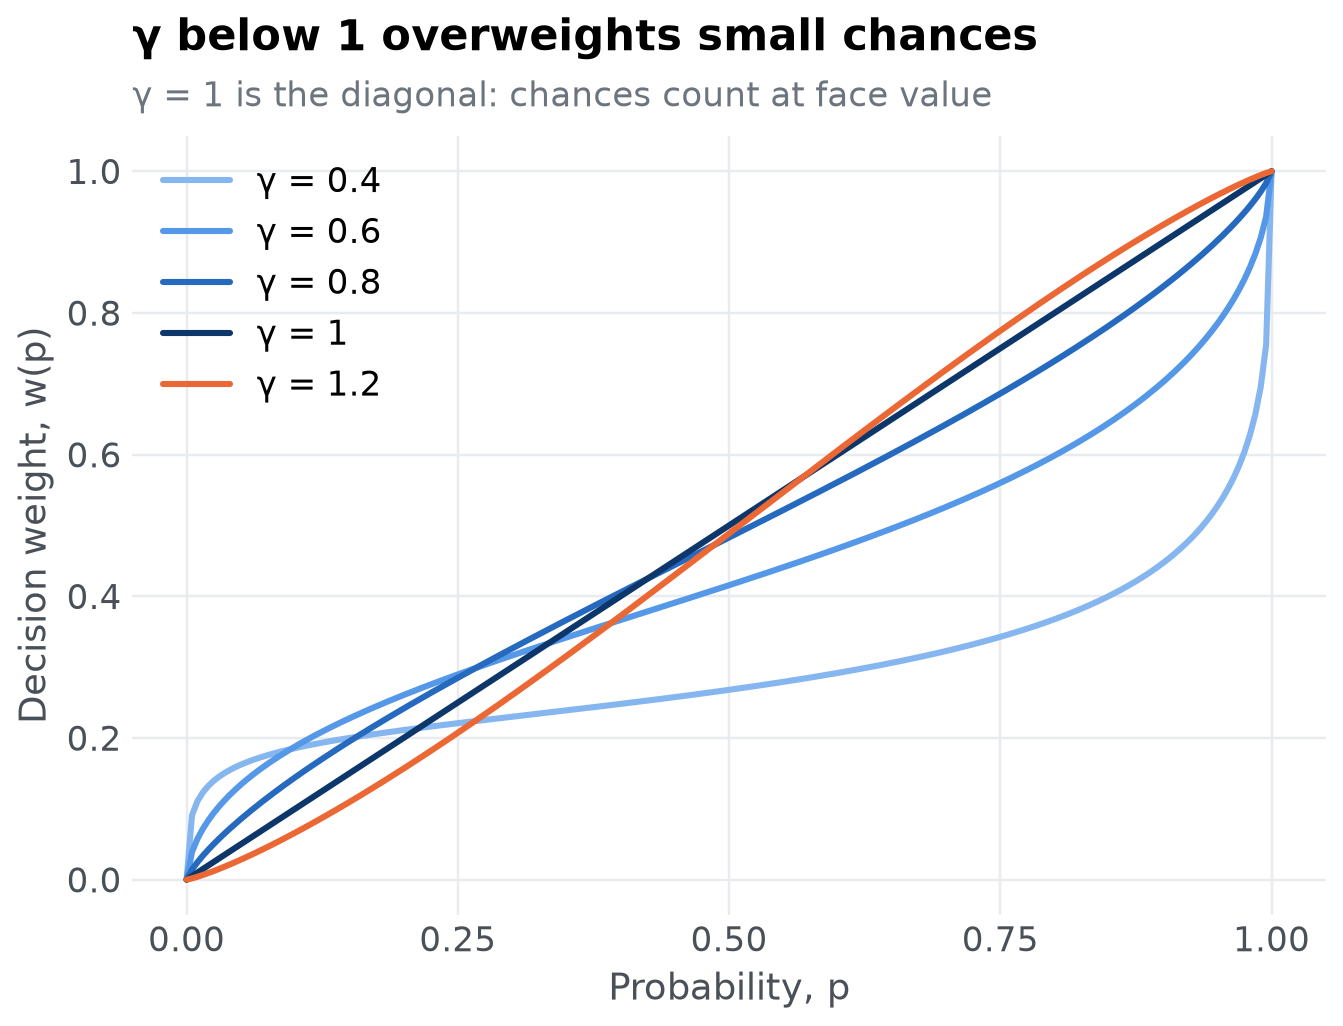

In [5]:
def weight(p, gamma):
    return p**gamma / (p**gamma + (1 - p) ** gamma) ** (1 / gamma)


gamma_colours = {0.4: "#86b6ef", 0.6: "#5598e7", 0.8: "#256abf", 1: "#0d366b", 1.2: "#eb6834"}
p = torch.linspace(0, 1, 201, dtype=torch.float64)
fig, ax = plt.subplots()
for g, colour in gamma_colours.items():
    ax.plot(p, weight(p, g), color=colour, linewidth=2, label=f"γ = {g}")
ax.set_xlabel("Probability, p")
ax.set_ylabel("Decision weight, w(p)")
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.legend()
titled(ax, "γ below 1 overweights small chances", "γ = 1 is the diagonal: chances count at face value")
show(fig, "weighting-function")

### Choosing

In each problem, prospect theory chooses the option with the higher value. Write $(x_R, p_R)$ for the riskier option and $(x_S, p_S)$ for the safer one. The model's prediction for the problem is the difference

$$
\Delta = V(x_R, p_R) - V(x_S, p_S),
$$

and it chooses the riskier option when $\Delta > 0$ and the safer one when $\Delta < 0$.

Expected utility theory is the special case $\gamma = 1$, where chances count at face value. Keep that in mind: everything we learn about prospect theory along the line $\gamma = 1$ is also a statement about expected utility theory.

### In Python

The model takes the two parameters, $\alpha$ and $\gamma$, and returns $\Delta$ for each of the four problems. One difference from the R package: `PSP()` hands the model a whole *batch* of parameter sets at once, one per row of a tensor, and expects one row of outputs per parameter set. That is what lets the search run on a GPU. Written with broadcasting, the batched model is no longer than the single-set one:

In [6]:
risky_amount = torch.tensor(problems.risky_amount.to_numpy(), dtype=torch.float64)
risky_chance = torch.tensor(problems.risky_chance.to_numpy(), dtype=torch.float64)
safe_amount = torch.tensor(problems.safe_amount.to_numpy(), dtype=torch.float64)
safe_chance = torch.tensor(problems.safe_chance.to_numpy(), dtype=torch.float64)


def prospect_value(amount, chance, alpha, gamma):
    return weight(chance, gamma) * amount**alpha


def model(par):
    """par: one parameter set per row, columns alpha and gamma. Returns one row of four deltas per set."""
    alpha = par[:, :1]
    gamma = par[:, 1:]
    return prospect_value(risky_amount, risky_chance, alpha, gamma) - prospect_value(safe_amount, safe_chance, alpha, gamma)

Tversky and Kahneman (1992) estimated $\alpha = 0.88$ and $\gamma = 0.61$ from people's choices. At those values, the model predicts:

In [7]:
estimates = torch.tensor([[0.88, 0.61]], dtype=torch.float64)
torch.round(model(estimates))

tensor([[-250.,   52.,   18.,    6.]], dtype=torch.float64)

Positive values mean the riskier option. So the model chooses the riskier option in Problems 4, 7 and 8, and the safer one in Problem 3. The published estimates get three of the four majority choices right, but not Problem 7. Is that a limit of prospect theory, or just of these particular values? PSP answers that by looking across all parameter values, not just one.

## From predictions to patterns

`PSP()` needs a second function, `discretize`, that turns the model's predictions into an *ordinal pattern*: the qualitative outcome we care about, stored as a square numeric matrix. Here the outcome is the choice in each problem: $+1$ for the riskier option and $-1$ for the safer one, the sign of each $\Delta$. We put the four signs on the diagonal of a 4 × 4 matrix, one problem per row. Like `model`, `discretize` works on a batch: a row of deltas in, a matrix out, for every parameter set at once.

In [8]:
def discretize(delta):
    return torch.diag_embed(torch.sign(delta))


discretize(model(estimates))[0]

tensor([[-1.,  0.,  0.,  0.],
        [ 0.,  1.,  0.,  0.],
        [ 0.,  0.,  1.,  0.],
        [ 0.,  0.,  0.,  1.]], dtype=torch.float64)

Two parameter sets produce the same pattern when their matrices are identical. Matrices are hard to read, so here is a function that describes a pattern by the problems in which the model takes the riskier option:

In [9]:
def describe(pattern):
    riskier = [int(p) for p, choice in zip(problems.problem, torch.diagonal(pattern)) if choice > 0]
    if not riskier:
        return "Always safer"
    if len(riskier) == 4:
        return "Always riskier"
    if len(riskier) == 1:
        return f"Riskier in Problem {riskier[0]} only"
    return "Riskier in Problems " + ", ".join(map(str, riskier[:-1])) + f" and {riskier[-1]}"


describe(discretize(model(estimates))[0])

'Riskier in Problems 4, 7 and 8'

In the same terms, what most people chose is

In [10]:
human = describe(torch.diag(torch.tensor([1.0 if c > 50 else -1.0 for c in problems.chose_risky])))
human

'Riskier in Problems 4 and 8'

With four problems and two choices each there are $2^4 = 16$ conceivable patterns. Which of them can prospect theory produce?

## Searching the parameter space

The `control` dictionary tells `PSP()` where to search and when to stop. It takes the same keys as the `control` list of the R package:

In [11]:
torch.manual_seed(2026)
control = {
    "lower": [0.2, 0.3],
    "upper": [1, 1.2],
    "init": torch.stack([torch.rand(5) * 0.8 + 0.2, torch.rand(5) * 0.9 + 0.3], dim=1),
    "radius": 0.5,
    "population": 200,
    "iterations": 30000,
    "parameter_names": ["alpha", "gamma"],
    "stimuli_names": [f"problem{p}" for p in problems.problem],
    "dimensionality": 4,
    "responses": 4,
}

- `lower` and `upper` are the bounds of each parameter: $\alpha$ from 0.2 to 1, and $\gamma$ from 0.3 to 1.2. Below about 0.28, $w(p)$ stops increasing with $p$, so we stay above that.
- `init` holds the starting points, one parameter set per row. Here there are five random ones.
- `radius` is the largest step the search takes, in any one parameter, from a pattern's most recent parameter set.
- `population` is the number of parameter sets each pattern needs. Once a pattern has that many, the search stops proposing new points from it, and it ends when every pattern it found is full.
- `iterations` caps the search in case some pattern never fills.
- `dimensionality` is the size of the matrix `discretize` returns, and `responses` the length of the row `model` returns: 4 and 4. (These two are optional in the Python package; when given, every evaluation is checked against them.)
- `parameter_names` and `stimuli_names` name the columns of the files written with `save=True`.

With `save=True`, every parameter set the search evaluates is written to disk, so we can see where it went:

In [12]:
path = Path(tempfile.mkdtemp()) / "prospect"
result = PSP(model, discretize, control, save=True, path=path, quiet=True)
result

PSPResult(patterns=8, evaluations=13572, iterations=11913)

The result holds each pattern found (`ordinal_patterns`, one matrix per pattern), how many parameter sets produced it (`ordinal_counts`), and the number of iterations (`iterations`). It can be indexed like the R list, `result["ordinal_counts"]`, or by attribute, `result.ordinal_counts`.

In [13]:
found = pd.DataFrame({
    "pattern": [describe(p) for p in result.ordinal_patterns],
    "parameter_sets": result.ordinal_counts.tolist(),
})
stopped = (f"stopped on its own after {result.iterations:,} iterations" if result.iterations < control["iterations"]
           else "stopped at the iteration cap")
display(Markdown(f"The search found **{result.patterns} patterns** and {stopped}, "
                 f"having evaluated the model {result.evaluations:,} times:"))
found

The search found **8 patterns** and stopped on its own after 11,913 iterations, having evaluated the model 13,572 times:

,pattern,parameter_sets
0,Always safer,1580
1,"Riskier in Problems 4, 7 and 8",2933
2,Riskier in Problem 4 only,1254
3,Riskier in Problems 4 and 8,1141
4,Riskier in Problems 3 and 4,2933
5,Riskier in Problem 3 only,1446
6,Always riskier,2085
7,"Riskier in Problems 3, 4 and 8",200


In [14]:
# fixed colours, so a pattern keeps its colour in every figure; the human pattern is blue
pattern_levels = ["Riskier in Problems 4 and 8", "Always safer", "Riskier in Problem 4 only",
                  "Riskier in Problems 4, 7 and 8", "Riskier in Problems 3 and 4",
                  "Riskier in Problem 3 only", "Always riskier", "Riskier in Problems 3, 4 and 8"]
pattern_levels += [p for p in found.pattern if p not in pattern_levels]
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948", "#666666"]
pattern_colours = {level: palette[min(i, len(palette) - 1)] for i, level in enumerate(pattern_levels)}

In [15]:
display(Markdown(f"The pattern most people chose, *{human}*, is {'among them' if human in set(found.pattern) else 'not among them'}. "
                 "So prospect theory *can* reproduce what most people chose, even though the published estimates do not. "
                 "Laid out problem by problem, the patterns look like this:"))

The pattern most people chose, *Riskier in Problems 4 and 8*, is among them. So prospect theory *can* reproduce what most people chose, even though the published estimates do not. Laid out problem by problem, the patterns look like this:

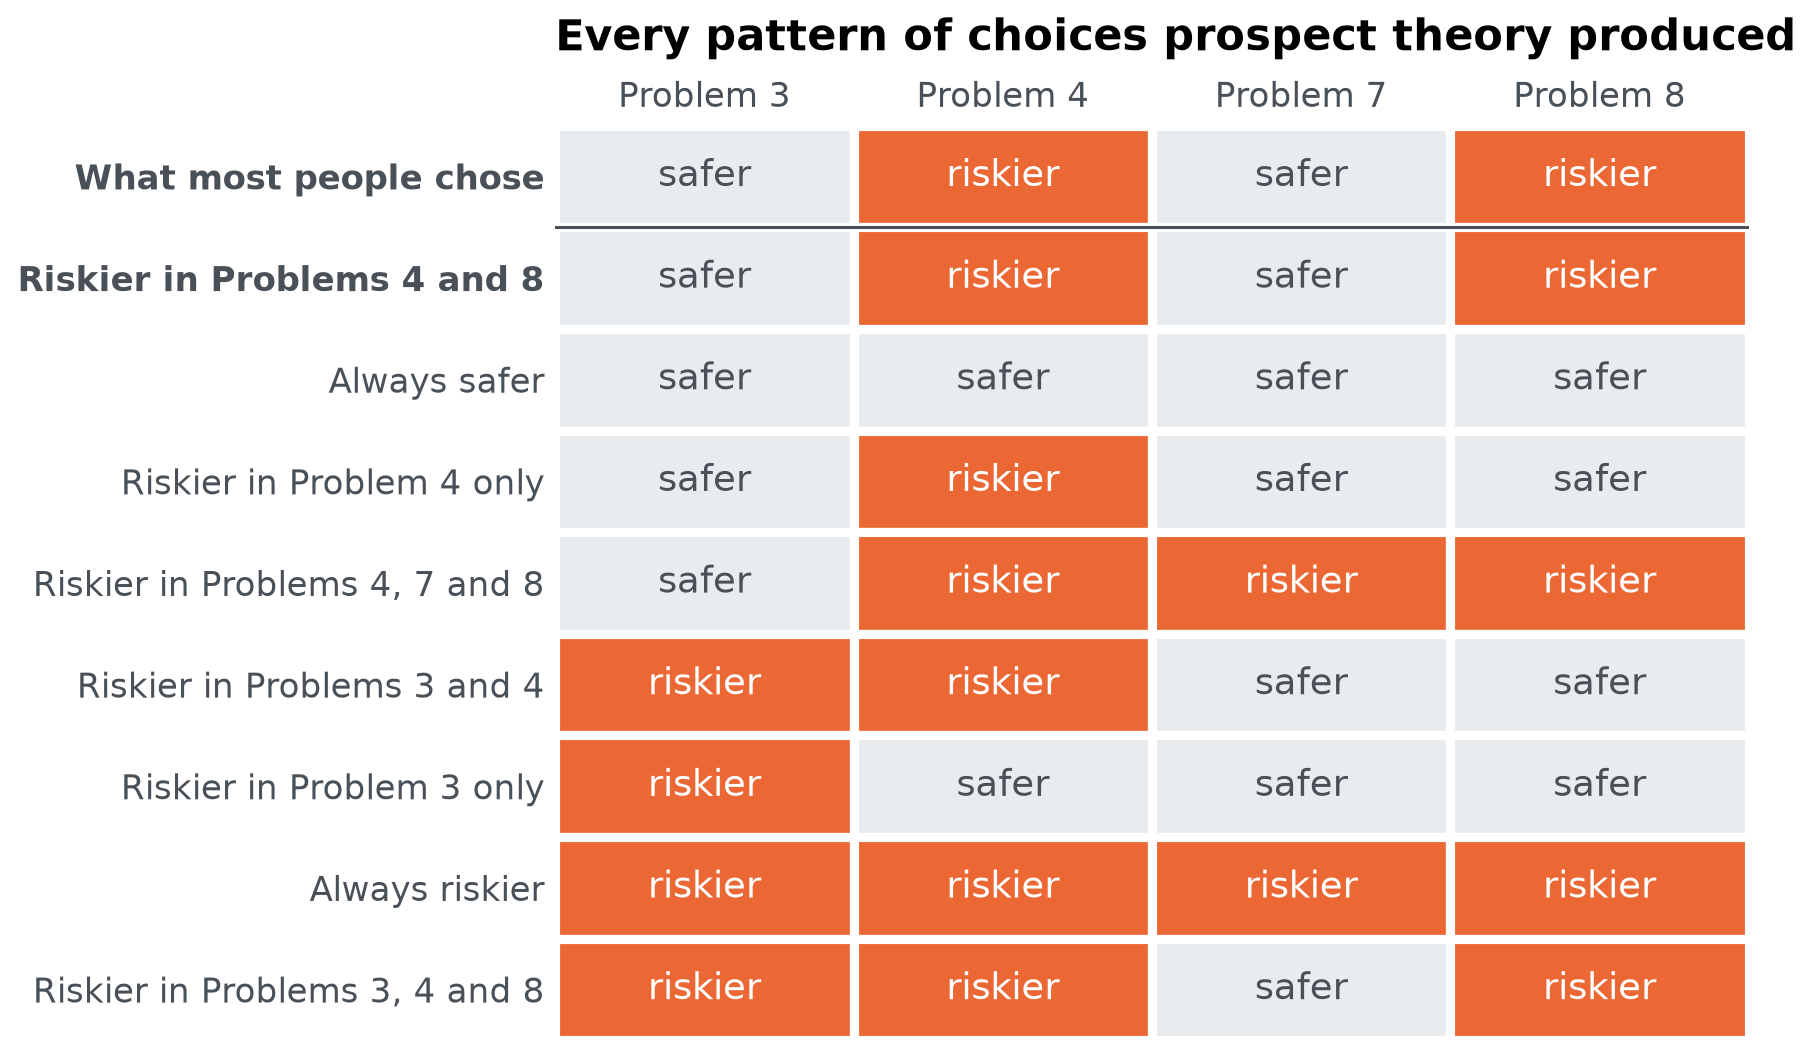

In [16]:
rows = ["What most people chose"] + [p for p in pattern_levels if p in set(found.pattern)]
choices = {"What most people chose": [c > 50 for c in problems.chose_risky]}
for pattern, name in zip(result.ordinal_patterns, found.pattern):
    choices[name] = [v > 0 for v in torch.diagonal(pattern).tolist()]
fig, ax = plt.subplots(figsize=(7, 5.4))
for i, name in enumerate(rows):
    y = len(rows) - 1 - i
    for j, riskier in enumerate(choices[name]):
        ax.add_patch(mpatches.Rectangle((j, y), 1, 1, facecolor="#eb6834" if riskier else "#e9ecef", edgecolor="white", linewidth=3))
        ax.text(j + 0.5, y + 0.5, "riskier" if riskier else "safer", ha="center", va="center",
                color="white" if riskier else "#495057")
ax.axhline(len(rows) - 1, color="#495057", linewidth=1)
ax.set_xlim(0, 4)
ax.set_ylim(0, len(rows))
ax.set_xticks(np.arange(4) + 0.5, labels)
ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(rows)) + 0.5, rows[::-1])
for tick in ax.get_yticklabels():
    if tick.get_text() in (human, "What most people chose"):
        tick.set_fontweight("bold")
ax.grid(False)
titled(ax, "Every pattern of choices prospect theory produced")
show(fig, "patterns-found")

## Seeing the partition

The saved file has one row per evaluated parameter set, with the number of the pattern it produced (0-based, the index into `result.ordinal_patterns`). With two parameters, plotting those rows draws the model's map. Because this model is so cheap, we can also check that map against brute force: evaluate it on a fine grid of 200 × 200 parameter sets. Batched evaluation makes that a single call:

In [17]:
alpha_grid, gamma_grid = torch.meshgrid(torch.linspace(0.2, 1, 200, dtype=torch.float64),
                                        torch.linspace(0.3, 1.2, 200, dtype=torch.float64), indexing="ij")
grid = pd.DataFrame({"alpha": alpha_grid.reshape(-1), "gamma": gamma_grid.reshape(-1)})
grid_patterns = discretize(model(torch.tensor(grid.to_numpy())))
signs = torch.diagonal(grid_patterns, dim1=1, dim2=2)
grid["pattern"] = [describe(torch.diag(s)) for s in signs]

In [18]:
# expected utility: gamma exactly 1 (alpha = 1 itself is left out, where Problems 7 and 8 tie)
eu_alphas = torch.linspace(0.2, 1, 801, dtype=torch.float64)[:-1]
eu_patterns = sorted({describe(p) for p in discretize(model(torch.stack([eu_alphas, torch.ones_like(eu_alphas)], dim=1)))})
eu_text = " or ".join(f"*{p}*" for p in eu_patterns)

evaluated = read_saved(path).parameters
evaluated["pattern"] = found.pattern.to_numpy()[evaluated.pattern]


def landmarks(ax):
    """What both maps share: the expected-utility line, the published estimates, axes and legend."""
    ax.axhline(1, color="black", linewidth=1)
    ax.text(0.21, 1.035, "expected utility (γ = 1)", fontsize=11, va="bottom", backgroundcolor="white")
    ax.plot(0.88, 0.61, "o", markersize=9, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.4)
    ax.text(0.86, 0.55, "published estimates", fontsize=11, ha="right", backgroundcolor="white")
    ax.set_xlim(0.2, 1)
    ax.set_ylim(0.3, 1.2)
    ax.set_xlabel("α (diminishing sensitivity)")
    ax.set_ylabel("γ (probability weighting)")
    ax.grid(False)
    handles = [Line2D([], [], marker="s", linestyle="", markersize=10, color=pattern_colours[p], label=p)
               for p in pattern_levels if p in set(found.pattern) or p in set(grid.pattern)]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

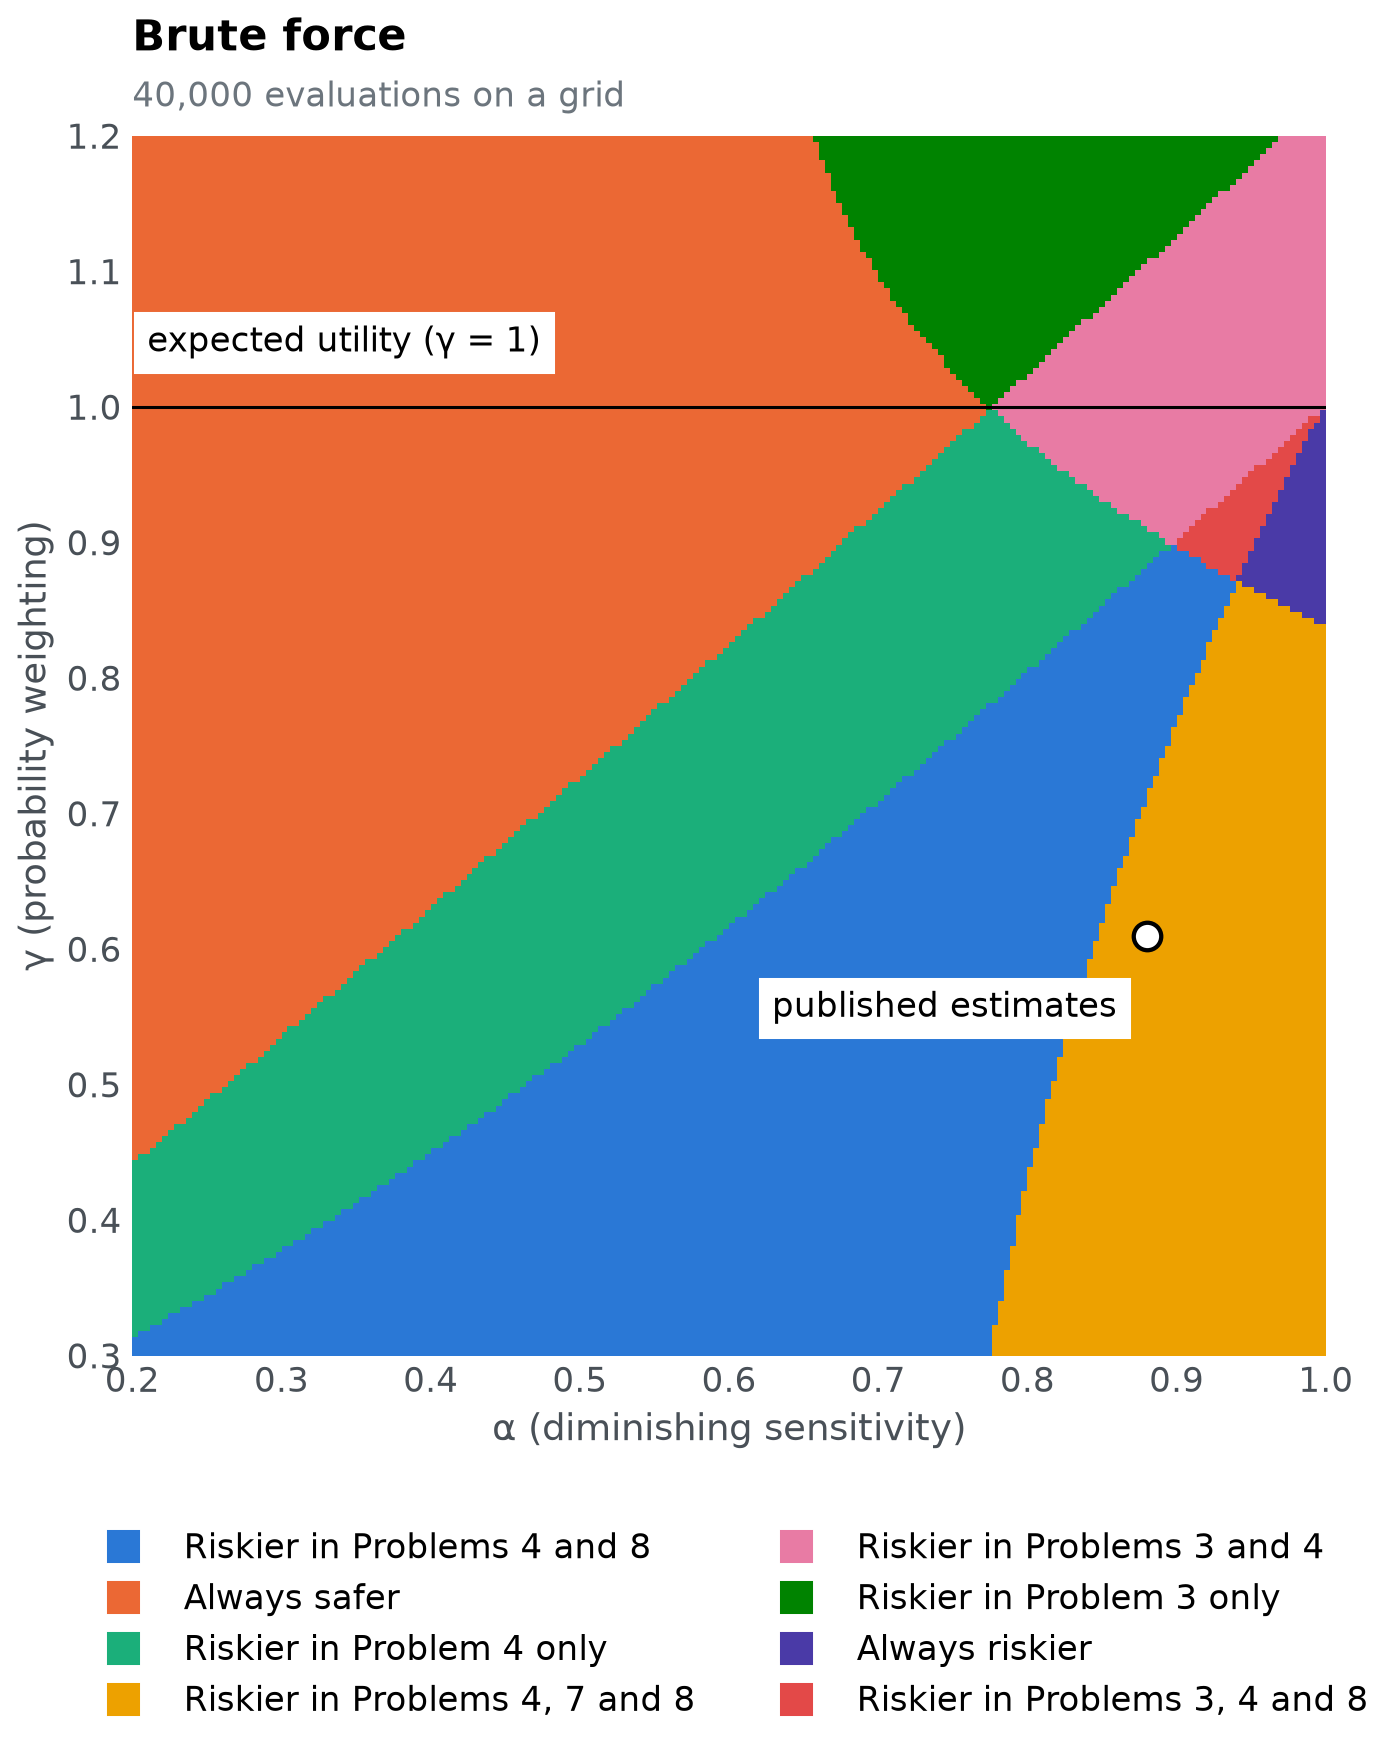

In [19]:
from matplotlib.colors import ListedColormap

levels = [p for p in pattern_levels if p in set(grid.pattern)]
index = grid.pattern.map({p: i for i, p in enumerate(levels)}).to_numpy().reshape(200, 200)
fig, ax = plt.subplots(figsize=(7, 7.2))
ax.imshow(index.T, origin="lower", extent=(0.2, 1, 0.3, 1.2), aspect="auto", interpolation="nearest",
          cmap=ListedColormap([pattern_colours[p] for p in levels]), vmin=-0.5, vmax=len(levels) - 0.5)
landmarks(ax)
titled(ax, "Brute force", "40,000 evaluations on a grid")
show(fig, "brute-force-map")

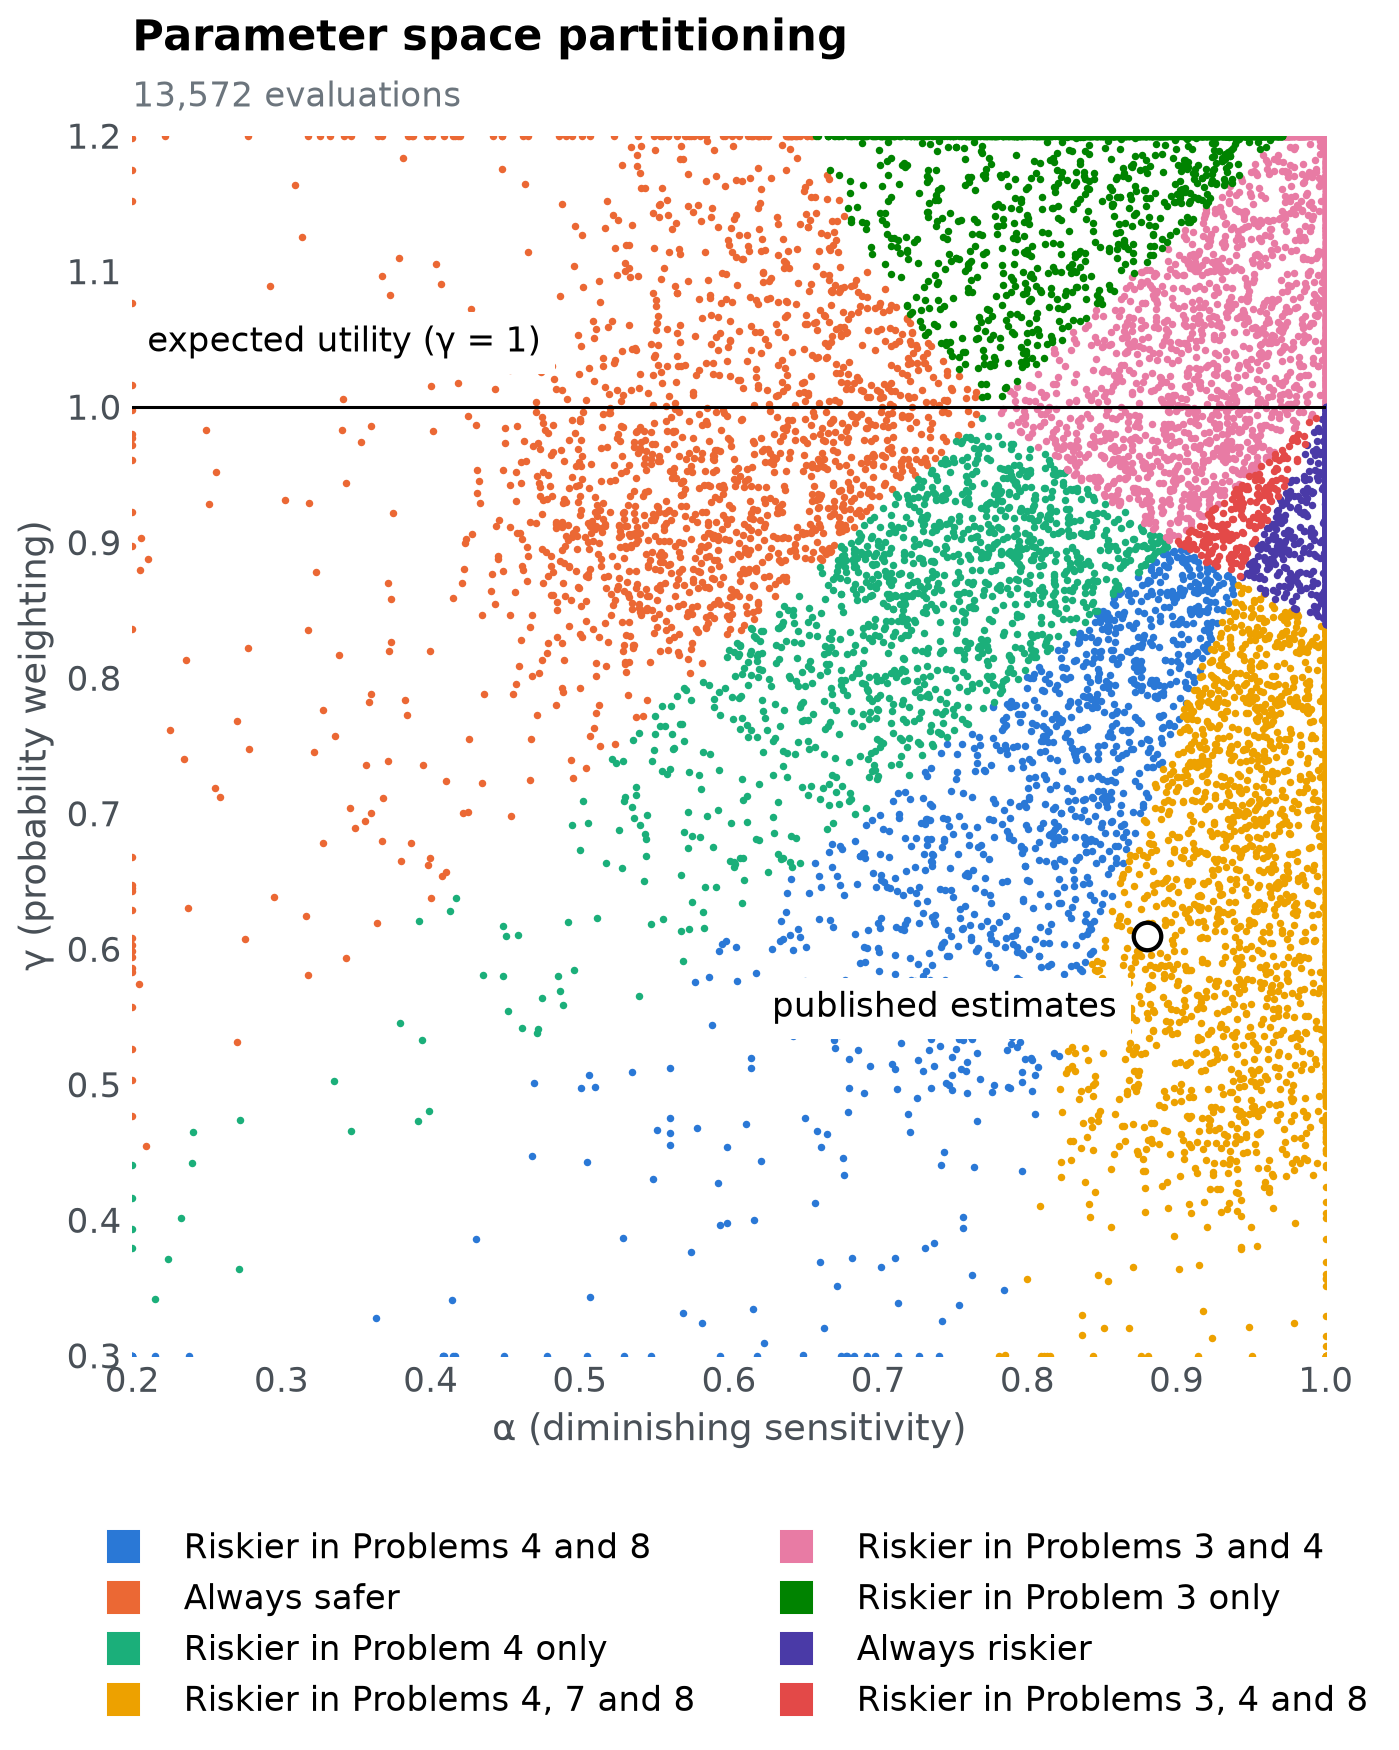

In [20]:
fig, ax = plt.subplots(figsize=(7, 7.2))
for p in pattern_levels:
    part = evaluated[evaluated.pattern == p]
    ax.scatter(part.alpha, part.gamma, s=6, color=pattern_colours[p], linewidths=0)
landmarks(ax)
titled(ax, "Parameter space partitioning", f"{len(evaluated):,} evaluations")
show(fig, "psp-map")

The two maps agree: PSP found every region the grid shows, with far fewer evaluations. Empty areas are places the search never sampled. That is expected: PSP needs `population` parameter sets for each pattern, not an even cover of the space, so a large region can be mapped with a few hundred points. With two parameters a grid is cheap, but its cost multiplies with every parameter: 200 values per parameter is 40,000 evaluations for two parameters, 8 million for three and 1.6 billion for four. PSP's cost grows mainly with the number of patterns instead, which is what makes it usable for real models.

The map also answers our questions at a glance:

In [21]:
display(Markdown(f"""
- **The pattern people chose (blue) covers a large region** of the parameter space, where $\\gamma$ is well below 1, so small chances are overweighted.
- **The published estimates sit just outside it**, in the neighbouring region, *{describe(discretize(model(estimates))[0])}*, which differs from people only in Problem 7. A small change in $\\alpha$ or $\\gamma$ moves them into the human region.
- **Expected utility, the line $\\gamma = 1$, never touches the human pattern.** Along it the model only ever produces {eu_text}.
"""))


- **The pattern people chose (blue) covers a large region** of the parameter space, where $\gamma$ is well below 1, so small chances are overweighted.
- **The published estimates sit just outside it**, in the neighbouring region, *Riskier in Problems 4, 7 and 8*, which differs from people only in Problem 7. A small change in $\alpha$ or $\gamma$ moves them into the human region.
- **Expected utility, the line $\gamma = 1$, never touches the human pattern.** Along it the model only ever produces *Always safer* or *Riskier in Problems 3 and 4*.


## Explore it yourself

Move the sliders to set $\alpha$ and $\gamma$. The panel shows the value prospect theory gives each option and the choice it makes. Can you find the parameter values where the model chooses as people did? (The sliders are live in a running notebook; a saved copy shows one setting.)

In [22]:
from ipywidgets import FloatSlider, interact


@interact(alpha=FloatSlider(value=0.88, min=0.2, max=1, step=0.005, description="α"),
          gamma=FloatSlider(value=0.61, min=0.3, max=1.2, step=0.005, description="γ"))
def explore(alpha, gamma):
    par = torch.tensor([[alpha, gamma]], dtype=torch.float64)
    risky = prospect_value(risky_amount, risky_chance, par[:, :1], par[:, 1:])[0]
    safe = prospect_value(safe_amount, safe_chance, par[:, :1], par[:, 1:])[0]
    pattern = discretize(risky - safe)[0]
    label = describe(pattern)
    fig, (ax, panel) = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.1, 1]})
    ax.imshow(index.T, origin="lower", extent=(0.2, 1, 0.3, 1.2), aspect="auto", interpolation="nearest",
              cmap=ListedColormap([pattern_colours[p] for p in levels]), vmin=-0.5, vmax=len(levels) - 0.5)
    ax.axhline(1, color="black", linewidth=1.5)
    ax.text(0.215, 1.03, "expected utility (γ = 1)", fontsize=10, va="bottom")
    ax.plot(alpha, gamma, "o", markersize=12, markerfacecolor="white", markeredgecolor="black", markeredgewidth=2)
    ax.set_xlim(0.2, 1); ax.set_ylim(0.3, 1.2); ax.set_xlabel("α"); ax.set_ylabel("γ"); ax.grid(False)
    panel.axis("off")
    mismatches = [int(p) for p, r, c in zip(problems.problem, torch.diagonal(pattern), problems.chose_risky)
                  if (r > 0) != (c > 50)]
    verdict = ("✓ Chooses as most people did in all four problems." if not mismatches
               else f"✗ Differs from most people in Problem{'s' if len(mismatches) > 1 else ''} {', '.join(map(str, mismatches))}.")
    panel.add_patch(mpatches.Rectangle((0.02, 0.86), 0.05, 0.08, color=pattern_colours.get(label, "#888"), transform=panel.transAxes))
    panel.text(0.1, 0.9, label, transform=panel.transAxes, fontsize=13, fontweight="bold", va="center")
    panel.text(0.02, 0.78, verdict, transform=panel.transAxes, fontsize=11, color="#495057", va="center")
    table = [[int(p), f"{r:,.0f}", f"{s:,.0f}", "riskier" if r > s else "safer", "riskier" if c > 50 else "safer"]
             for p, r, s, c in zip(problems.problem, risky.tolist(), safe.tolist(), problems.chose_risky)]
    t = panel.table(cellText=table, colLabels=["Problem", "Riskier", "Safer", "Model", "People"],
                    loc="center", bbox=[0.02, 0.15, 0.96, 0.5])
    t.auto_set_font_size(False); t.set_fontsize(11)
    for (row, col), cell in t.get_celld().items():
        cell.set_edgecolor("#dee2e6")
        if row > 0 and col == 3 and table[row - 1][3] == "riskier":
            cell.get_text().set_color("#c4521f"); cell.get_text().set_fontweight("bold")
    panel.text(0.02, 0.06, "Values are V(x, p) for each option, in the units of v(x).", transform=panel.transAxes,
               fontsize=9.5, color="#6c757d")
    plt.show()

interactive(children=(FloatSlider(value=0.88, description='α', max=1.0, min=0.2, step=0.005), FloatSlider(valu…

Watch how lowering $\gamma$ raises the value of the long shots in Problems 4 and 8 much more than the near-certain options in Problems 3 and 7.

## How the search explores

PSP is a Markov chain Monte Carlo search. Each pattern found so far proposes a new parameter set at random within `radius` of its most recent one, and every new pattern it finds gets proposals of its own in later iterations. Plotting the saved parameter sets after a few iterations shows the search spreading out from its five starting points:

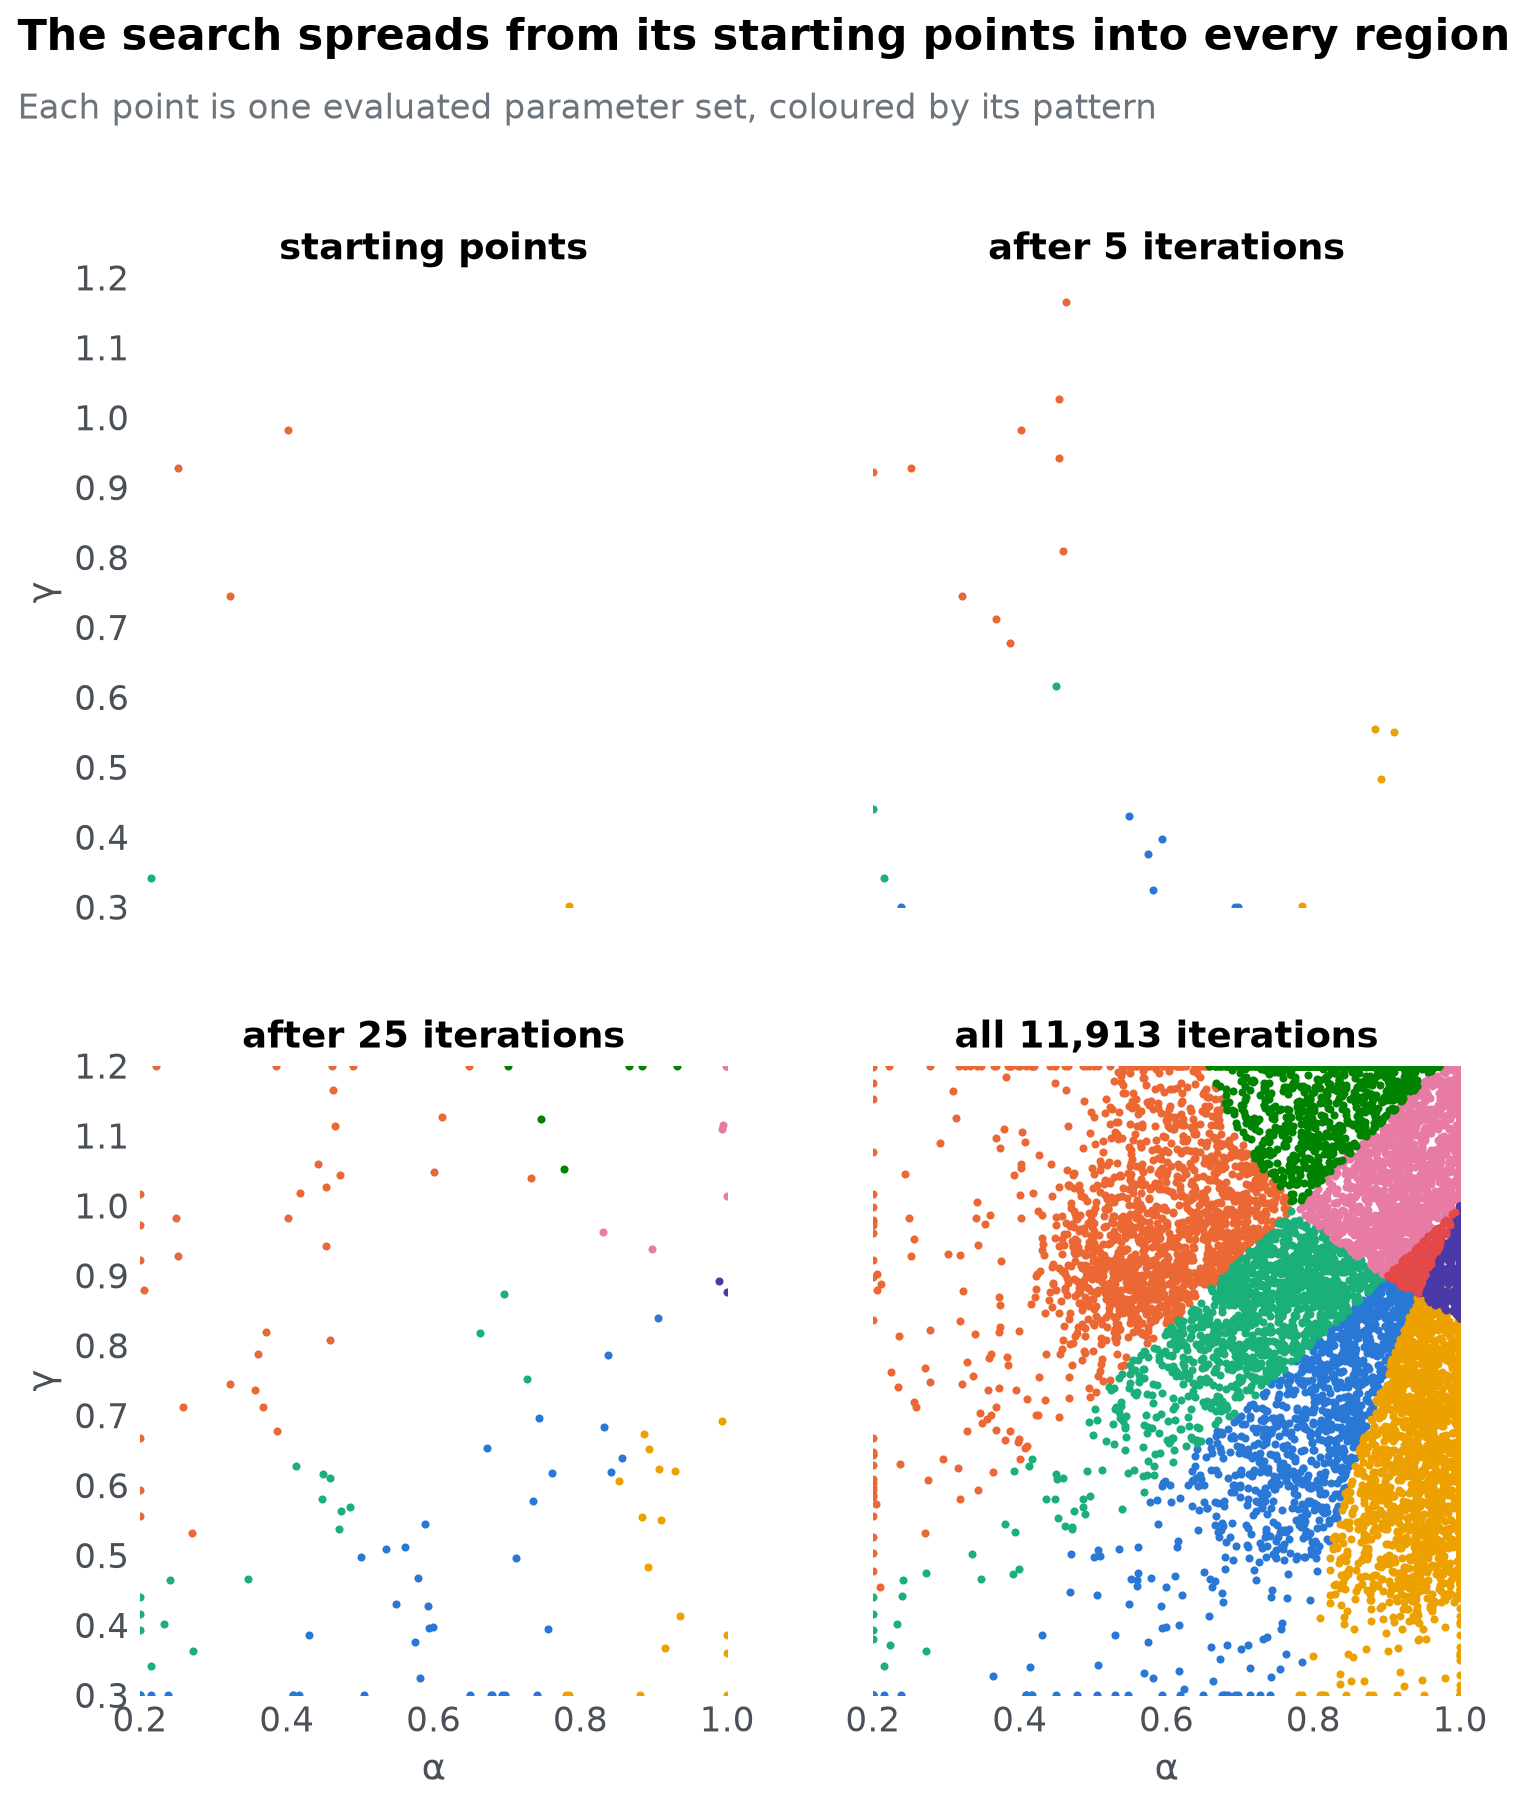

In [23]:
last = int(evaluated.iteration.max())
stages = [0, 5, 25, last]
fig, axes = plt.subplots(2, 2, figsize=(7, 8.4), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), stages):
    d = evaluated[evaluated.iteration <= s]
    for p in pattern_levels:
        part = d[d.pattern == p]
        ax.scatter(part.alpha, part.gamma, s=7, color=pattern_colours[p], linewidths=0)
    ax.set_xlim(0.2, 1); ax.set_ylim(0.3, 1.2); ax.grid(False)
    ax.set_title("starting points" if s == 0 else f"all {s:,} iterations" if s == last else f"after {s} iterations",
                 loc="center", fontsize=12)
for ax in axes[1]:
    ax.set_xlabel("α")
for ax in axes[:, 0]:
    ax.set_ylabel("γ")
fig.suptitle("The search spreads from its starting points into every region", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.925, "Each point is one evaluated parameter set, coloured by its pattern", color="#6c757d", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=2.5, w_pad=2.5)
show(fig, "search-progress")

Once a pattern has `population` parameter sets it stops proposing, so the later iterations spend their effort on the patterns that are still filling, usually the smallest regions.

## How much of the space produces each pattern?

The number of parameter sets PSP records for a pattern is **not** a measure of how much of the parameter space produces it. Every pattern is sampled until it reaches the same `population`, however large or small its region. To compare region sizes, sample the parameter space evenly. With this cheap model the grid does that already:

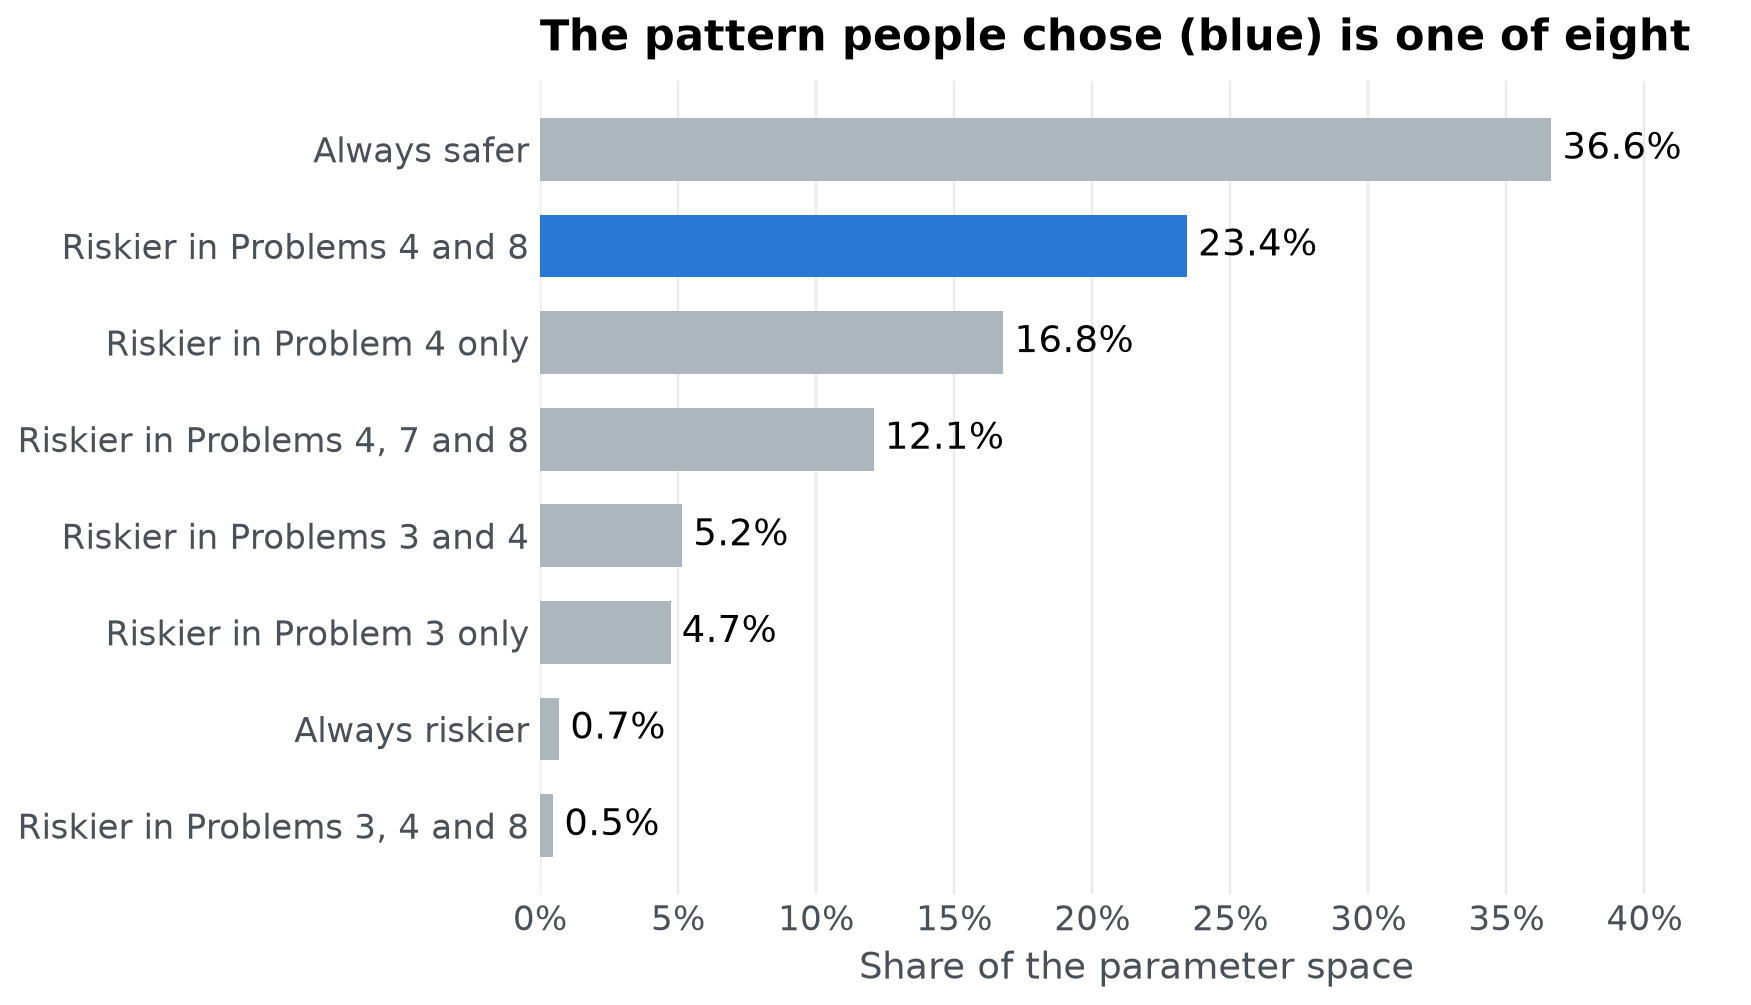

In [24]:
share = (grid.pattern.value_counts() / len(grid)).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(share.index, share.values, color=[blue if p == human else grey for p in share.index], height=0.65)
for y, value in enumerate(share.values):
    ax.text(value + 0.004, y, f"{value:.1%}", va="center")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, share.max() * 1.18)
ax.set_xlabel("Share of the parameter space")
ax.grid(axis="y", visible=False)
titled(ax, "The pattern people chose (blue) is one of eight")
show(fig, "pattern-shares")

For a model too expensive to evaluate on a grid, estimate the shares by sampling parameter sets uniformly within the bounds and counting the patterns they produce, using as many evaluations as you can afford. `psp` does not do this for you.

## What we learned

In [25]:
display(Markdown(f"""
Prospect theory can produce {grid.pattern.nunique()} of the 16 conceivable patterns of choices on these four problems. The pattern most people chose is one of them, and it comes from about {(grid.pattern == human).mean():.0%} of the parameter space. Expected utility theory, the line $\\gamma = 1$, cannot produce it at all. That is the qualitative case for prospect theory over expected utility in one figure.

The analysis also shows the price of that success. Prospect theory can produce patterns far from what people chose, such as taking the riskier option in all four problems. A fit to data hides this flexibility, while PSP makes it visible. To weigh a model's successes against its flexibility across many people, see g-distance (Dome & Wills, 2025).
"""))


Prospect theory can produce 8 of the 16 conceivable patterns of choices on these four problems. The pattern most people chose is one of them, and it comes from about 23% of the parameter space. Expected utility theory, the line $\gamma = 1$, cannot produce it at all. That is the qualitative case for prospect theory over expected utility in one figure.

The analysis also shows the price of that success. Prospect theory can produce patterns far from what people chose, such as taking the riskier option in all four problems. A fit to data hides this flexibility, while PSP makes it visible. To weigh a model's successes against its flexibility across many people, see g-distance (Dome & Wills, 2025).


## Did the search find everything?

PSP only finds patterns it can reach before every pattern it has found is full, so a single run can miss small or isolated regions. Here two regions each cover well under 1% of the space. The simplest check is to repeat the search with different starting points and pool the results:

In [26]:
runs = []
for seed in range(1, 5):
    torch.manual_seed(seed)
    control["init"] = torch.stack([torch.rand(5) * 0.8 + 0.2, torch.rand(5) * 0.9 + 0.3], dim=1)
    out = PSP(model, discretize, control, quiet=True)
    runs.append([describe(p) for p in out.ordinal_patterns])
print([len(r) for r in runs])
missed = set().union(*runs) - set(found.pattern)
print(missed)

[8, 8, 8, 8]
set()


In [27]:
display(Markdown(f"Four more runs found {', '.join(str(len(r)) for r in runs)} patterns, and "
                 f"{'none found a pattern the first run missed' if not missed else 'they found patterns the first run missed'}. "
                 "When further runs keep finding nothing new, you can be reasonably confident the map is complete."))

Four more runs found 8, 8, 8, 8 patterns, and none found a pattern the first run missed. When further runs keep finding nothing new, you can be reasonably confident the map is complete.

The `radius` sets a trade-off. Large steps reach distant regions quickly, but they fill small regions slowly, because most steps from a small region leave it again. Small steps fill regions quickly but explore slowly. Here is the same search with two radii, ten runs each:

In [28]:
def compare(radius):
    rows = []
    for seed in range(1, 11):
        torch.manual_seed(seed)
        control["init"] = torch.stack([torch.rand(5) * 0.8 + 0.2, torch.rand(5) * 0.9 + 0.3], dim=1)
        control["radius"] = radius
        out = PSP(model, discretize, control, quiet=True)
        rows.append({"patterns": out.patterns, "iterations": out.iterations})
    return pd.DataFrame(rows)


small = compare(0.1)
large = compare(0.5)
pd.DataFrame({
    "radius": [0.1, 0.5],
    "runs_finding_all_8": [(small.patterns == 8).sum(), (large.patterns == 8).sum()],
    "median_iterations": [small.iterations.median(), large.iterations.median()],
})

,radius,runs_finding_all_8,median_iterations
0,0.1,9,836.0
1,0.5,10,13008.5


If a run stops at the `iterations` cap, some pattern never filled. Usually that is a small region whose most recent parameter set sits near its edge, so most proposals from it land elsewhere. The [benchmarks](benchmarks.ipynb) compare how `population`, `radius` and the number of starting points affect what a search finds.

## References

Dome, L., & Wills, A. J. (2025). g-Distance: On the comparison of model and human heterogeneity. *Psychological Review, 132*(3), 632–655. <https://doi.org/10.1037/rev0000550>

Kahneman, D., & Tversky, A. (1979). Prospect theory: An analysis of decision under risk. *Econometrica, 47*(2), 263–291. <https://doi.org/10.2307/1914185>

Pitt, M. A., Kim, W., Navarro, D. J., & Myung, J. I. (2006). Global model analysis by parameter space partitioning. *Psychological Review, 113*(1), 57–83. <https://doi.org/10.1037/0033-295X.113.1.57>

Tversky, A., & Kahneman, D. (1992). Advances in prospect theory: Cumulative representation of uncertainty. *Journal of Risk and Uncertainty, 5*(4), 297–323. <https://doi.org/10.1007/BF00122574>